# Solutions of Class Exercises - Week 7

---
---

**Author:** Dr Giordano Scarciotti (g.scarciotti@imperial.ac.uk) - Imperial College London

**Module:** ELEC70066 - Applied Advanced Optimisation

**Version:** 1.1.2 - 20/02/2025

---
---

**Reminder:** The solutions of some these exercises may be found online. Do not look for the solutions, but ask for help to me or the GTA. Your assessment will not have a solution available online so it is of paramount importance that you learn how to solve the problems without relying on a solution being available.

The solutions of these exercises will be discussed at the end of the session. Moreover, the complete solution will be provided to you after 1 week.  **N.B.** **Do not share the solutions online**

## Exercise 1

Consider the quadratic programme

$$
\begin{array}{ll}
\min & x_1^2 + 2 x_2^2 - x_1 x_2 - x_1\\
s.t. & x_1 + 2x_2 \le u_1,\\
& x_1 - 4x_2 \le u_2,\\
& x_1 + x_2 \ge -5,
\end{array} \tag{1}
$$

with variables $x_1$, $x_2$ and parameters $u_1$ and $u_2$.

1.   Solve this QP, for parameter values $u_1 = -2$ and $u_2 = -3$. Print the optimal primal variables $x_1^*$ and $x_2^*$, the optimal dual variables $\lambda_1^*$, $\lambda_2^*$ and $\lambda_3^*$, and the optimal objective value $p^*$.
2.   Verify that the KKT conditions hold for the optimal primal and dual variables you found (within reasonable numerical accuracy).
3.   Consider the perturbed problem with
$$
u_1 = -2 + \delta_1,\qquad u_2=-3+\delta_2,
$$
where $\delta_1$ and $\delta_2$ take both values in the set $\{-0.1,0,0.1\}$ (there are a total of nine such combinations, including the original problem). For each combination of $\delta_1$ and $\delta_2$, make a prediction $p^*_{pred}$ of the optimal value of the perturbed QP, and compare it to $p^*_{exact}$ which is the exact optimal value of the perturbed QP (obtained by solving the perturbed QP). Complete the table:
$$
\begin{array}{|c|c|c|c|c|c|}\hline
& \delta_1 & \delta_2 & p^*_{pred} & p^*_{exact} & p^*_{exact}-p^*_{pred}\\\hline
1 & 0 & 0 & & & \\\hline
2 & 0 & -0.1 & & & \\\hline
3 & 0 & 0.1 & & & \\\hline
4 & -0.1 & 0 & & & \\\hline
5 & -0.1 & -0.1 & & & \\\hline
6 & -0.1 & 0.1 & & & \\\hline
7 & 0.1 & 0 & & & \\\hline
8 & 0.1 & -0.1 & & & \\\hline
9 & 0.1 & 0.1 & & & \\\hline
\end{array}
$$
Check that the inequality $p^*_{pred} \le p^*_{exact}$. For which perturbations (other than number $1$) is $p^*_{exact}-p^*_{pred}$ the smallest? *Tip: round to 5 decimals.*





### Solution Exercise 1

We solve the QP and find the primal and dual optimal variables, and the optimal value. The easiest way of solving this problem is by writing the QP in matrix form, i.e. finding matrices $P$, $G$, $q$ and $h$ such that

$$
\begin{array}{ll}
\min & \frac{1}{2}x^\top P x + q^\top x \\
s.t. & G x \preccurlyeq h
\end{array}
$$

To simplify the code, in the following we include $\frac{1}{2}$ within $P$.

Note that if we do not write the problem in matrix form we will have problems in the objective function when we try to evaluate $x_1 x_2$. In fact, CVXPY does not recognise this term as an operation following DCP rules (the same holds for $x_1^2$, but this specific issue can be avoided with `cp.square`).

In [ ]:
# Import libraries
import cvxpy as cp
import numpy as np

In [ ]:
# Declare variables and matrices of the QP
x = cp.Variable(2)
P = np.array([[1, -1/2], [-1/2, 2]])
G = np.array([[1, 2], [1, -4], [-1, -1]])
q = np.array([-1, 0])
h = np.array([-2, -3, 5])

In [ ]:
# Define constrains, problem and solve it
constraints = [G @ x <= h]
prob = cp.Problem(cp.Minimize(cp.quad_form(x, P)+ q.T @ x),constraints)
prob.solve()

#Find optimal value and dual variables
OptVal = prob.value
DualVar = constraints[0].dual_value

# Print result.
print("\nThe optimal value is", np.round(OptVal,2))
print("The optimal x is",np.round(x.value,2))
print("Dual variables", np.round(DualVar,2))


The optimal value is 8.22
The optimal x is [-2.33  0.17]
Dual variables [3.39 2.44 0.  ]


We now verify that the KKT conditions hold for the optimal primal and dual variables found.

In [ ]:
x1=x.value[0]
x2=x.value[1]
l1=DualVar[0]
l2=DualVar[1]
l3=DualVar[2]

print('KKT conditions:')
print("Constraint nonpositivity: ", G @ x.value - h <=0)
print("Nonnegativity of dual variables: ", DualVar >=0)
print("Complementary: ", DualVar * (G @ x.value-h) == 0)
print("Gradient: ", 2*x.value.T@P+q.T+DualVar@G==0)
#print("Gradient: ", np.array([[2*x1-x2-1],[4*x2 - x1]])+np.array([[l1+l2-l3],[2*l1-4*l2-l3]])==0)

KKT conditions:
Constraint nonpositivity:  [ True  True  True]
Nonnegativity of dual variables:  [ True  True  True]
Complementary:  [ True  True  True]
Gradient:  [ True  True]


We now solve the perturbed problem

In [ ]:
# Generate the solutions and prediction for each of the 9 perturbed problems.
delta = np.array([0,-0.1,0.1])
N=3
for i in range(N):
  for j in range(N):
    h = np.array([-2+delta[i], -3+delta[j], 5])
    constraints = [G @ x <= h]
    prediction = OptVal - DualVar @ np.array([delta[i], delta[j], 0])
    prob = cp.Problem(cp.Minimize(cp.quad_form(x, P)+ q.T @ x),constraints)
    prob.solve()
    print("Line", i*3+j+1 ,"- Delta1:",delta[i], "Delta2:", delta[j], "Prediction:",
          np.round(prediction,5),  "Exact value:",np.round(prob.value,5), "Prediction gap:", np.round(prob.value - prediction,5))

Line 1 - Delta1: 0.0 Delta2: 0.0 Prediction: 8.22222 Exact value: 8.22222 Prediction gap: 0.0
Line 2 - Delta1: 0.0 Delta2: -0.1 Prediction: 8.46667 Exact value: 8.46889 Prediction gap: 0.00222
Line 3 - Delta1: 0.0 Delta2: 0.1 Prediction: 7.97778 Exact value: 7.98 Prediction gap: 0.00222
Line 4 - Delta1: -0.1 Delta2: 0.0 Prediction: 8.56111 Exact value: 8.565 Prediction gap: 0.00389
Line 5 - Delta1: -0.1 Delta2: -0.1 Prediction: 8.80556 Exact value: 8.81556 Prediction gap: 0.01
Line 6 - Delta1: -0.1 Delta2: 0.1 Prediction: 8.31667 Exact value: 8.31889 Prediction gap: 0.00222
Line 7 - Delta1: 0.1 Delta2: 0.0 Prediction: 7.88333 Exact value: 7.88722 Prediction gap: 0.00389
Line 8 - Delta1: 0.1 Delta2: -0.1 Prediction: 8.12778 Exact value: 8.13 Prediction gap: 0.00222
Line 9 - Delta1: 0.1 Delta2: 0.1 Prediction: 7.63889 Exact value: 7.64889 Prediction gap: 0.01


All prediction gaps are nonnegative, so the inequality $p^*_{pred} \le p^*_{exact}$ is satisfied. The best predictions are achieved for perturbations number $2$, $3$, $6$ and $8$.

# Exercise 2

This exercise is mostly done with pen and paper.

Consider the optimisation problem

$$
\begin{array}{ll}
\min & x^2+1\\
s.t. & (x-2)(x-4) \le 0,
\end{array}
$$

with variable $x\in\mathbb{R}$.
1.    Give the feasible set, the optimal value, and the optimal solution. Plot the objective $x^2+1$ versus $x$. On the same plot, show the feasible set, optimal point and value.
2.    Plot the Lagrangian $L(x, \lambda)$ versus $x$ for a few positive values of $\lambda$. Verify the lower bound property ($p^* \ge \inf_x L(x, \lambda)$ for $\lambda\ge 0$). Derive and sketch the Lagrange dual function $g$.
3.    State the dual problem, and verify that it is a concave maximization problem. Find the dual optimal value and dual optimal solution $\lambda^*$. Does strong duality hold?
4.    Let $p^*(u)$ denote the optimal value of the perturbed problem
$$
\begin{array}{ll}
\min & x^2+1\\
s.t. & (x-2)(x-4) \le u
\end{array}
$$
as a function of the parameter $u$. Plot $p^*(u)$. Verify that $\frac{dp^*}{du}(0) = −\lambda^*$.

### Solution Exercise 2

**Part 1**

The feasible set is the interval $[2; 4]$. The (unique) optimal point is $x^* = 2$, and the
optimal value is $p^* = 5$.
The plot below shows $f_0$, $f_1$, the feasible set (in grey) and the optimal value.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

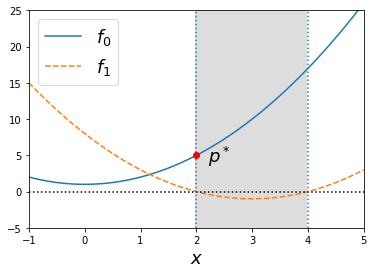

In [ ]:
N=56
for i in range(N):
  plt.axvline(x=2+2/N*i,linestyle='-',color="lightgrey")
plt.plot(np.linspace(-1, 5, 100),[x*x+1 for x in np.linspace(-1, 5, 100)],label="$f_0$")
plt.plot(np.linspace(-1, 5, 100),[(x-2)*(x-4) for x in np.linspace(-1, 5, 100)],linestyle='--',label="$f_1$")
plt.plot(np.linspace(-1, 5, 100),[0 for x in np.linspace(-1, 5, 100)],linestyle=':',color="black")
plt.axvline(x=2,linestyle=':')
plt.axvline(x=4,linestyle=':')
plt.plot(2,5,"ro")
plt.text(2.2, 4, "$p^*$",fontsize="18")
plt.legend(fontsize="18")
plt.xlabel("$x$",fontsize="18")
plt.xlim(-1,5)
plt.ylim(-5,25)
plt.show()

**Part 2**

The Lagrangian is
$$
L(x,\lambda) = (1+\lambda)x^2 - 6\lambda x + (1+8\lambda).
$$
The plot below shows the Lagrangian $L(x,\lambda) = f_0 +\lambda f_1$ as a function of $x$ for diff
erent
values of $\lambda\ge0$. Note that the minimum value of $L(x,\lambda)$ over $x$ (i.e., $g(\lambda)$) is always
less than $p^*$. It increases as $\lambda$ varies from $0$ towards $2$, reaches its maximum at $\lambda= 2$,
and then decreases again as $\lambda$ increases above $2$. We have equality $p^* = g(\lambda)$ for $\lambda=2$.

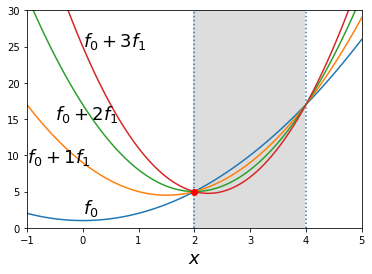

In [ ]:
N=56
M=4
for i in range(N):
  plt.axvline(x=2+2/N*i,linestyle='-',color="lightgrey")
for j in range(M):
  l=j
  plt.plot(np.linspace(-1, 5, 100),[(1+l)*x*x - 6*l*x + (1+8*l) for x in np.linspace(-1, 5, 100)])
plt.axvline(x=2,linestyle=':')
plt.axvline(x=4,linestyle=':')
plt.plot(2,5,"ro")
plt.text(0, 2, "$f_0$",fontsize="18")
plt.text(-1, 9, "$f_0+1f_1$",fontsize="18")
plt.text(-0.5, 15, "$f_0+2f_1$",fontsize="18")
plt.text(0, 25, "$f_0+3f_1$",fontsize="18")
plt.xlabel("$x$",fontsize="18")
plt.ylim(0,30)
plt.xlim(-1,5)
plt.show()

For $\lambda >-1$, the Lagrangian reaches its minimum at $\tilde{x} = 3 \lambda / (1+\lambda)$. For $\lambda \le -1$ it is unbounded below. Thus

$$
g(\lambda) = \left\{\begin{array}{ll}\frac{-9\lambda^2}{1+\lambda}+1+8\lambda & \lambda> -1\\
-\infty & \lambda \le -1\end{array}\right.
$$

which is plotted below.

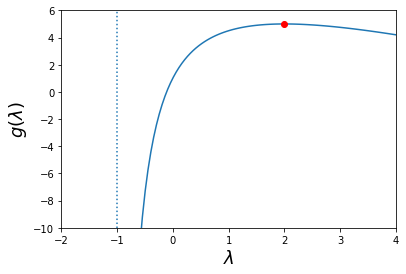

In [ ]:
plt.plot(np.linspace(-1, 4, 100),[-9*l*l/(1+l) +1 +8*l for l in np.linspace(-1+0.001, 4, 100)])
plt.axvline(x=-1,linestyle=':')
plt.plot(2,5,"ro")
plt.xlabel("$\lambda$",fontsize="18")
plt.ylabel("$g(\lambda)$",fontsize="18")
plt.ylim(-10,6)
plt.xlim(-2,4)
plt.show()

We can verify that the dual function is concave, that its value is equal to $p^*= 5$ for $\lambda=2$, and less than $p^*$ for other values of $\lambda$.

**Part 3**

The Lagrange dual problem is

$$
\begin{array}{ll}
\max & \displaystyle\frac{-9\lambda^2}{1+\lambda}+1+8\lambda\\
s.t. & \lambda\ge 0.
\end{array}
$$

The dual optimum occurs at $\lambda^*=2$, with $d^*= 5$. So for this example we can directly observe that strong duality holds (as it must as Slater's constraint quali
cation is satisfi
ed).

**Part 4**

The perturbed problem is infeasible for $u < -1$, since $\inf_x(x^2-6x + 8) =-1$. For $u\ge -1$, the feasible set is the interval
$$
[3- \sqrt{1 + u}, 3 + \sqrt{1 + u}],
$$
given by the two roots of $x^2-6x + 8 = u$. For $-1 \le u \le 8$ the optimum is $x^*(u) = 3 - \sqrt{1 + u}$ (the closest point in the feasible set to the minimiser of $f_0$, i.e. $x^* = 0$). For $u \ge 8$, the optimum is the unconstrained minimum of $f_0$,
i.e. $x^*(u) = 0$. In summary,

$$
p^*(u) = \left\{\begin{array}{ll}\infty & u < -1\\
11+u - 6 \sqrt{1+u} & -1 \le u \le 8\\
1 & u \ge 8\end{array}\right.
$$

The figure below shows the optimal value function $p^*(u)$. Finally, we note that $p^*(u)$ is a di
fferentiable function of $u$, and that
$$
\frac{dp^*}{du}(0)=\left.1-\frac{3}{\sqrt{1+u}}\right|_{u=0} =-2=-\lambda^*.
$$

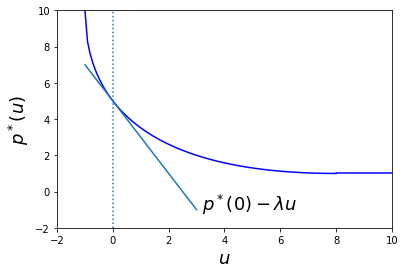

In [ ]:
plt.plot(np.linspace(-1, 8, 100),[11+u-6*np.sqrt(1+u) for u in np.linspace(-1, 8, 100)],color="b")
plt.plot(np.linspace(8, 10, 20),[1 for u in np.linspace(8, 10, 20)],color="b")
plt.plot(np.linspace(-1, 3, 100),[5-2*u for u in np.linspace(-1, 3, 100)])
plt.axvline(x=0,linestyle=':')
plt.text(3.2, -1, "$p^*(0)-\lambda u$",fontsize="18")
plt.xlabel("$u$",fontsize="18")
plt.ylabel("$p^*(u)$",fontsize="18")
plt.ylim([-2,10])
plt.xlim([-2,10])
plt.show()

## Exercise 3

Find the dual function of the LP
$$
\begin{array}{ll}
\min & c^\top x\\
s.t. & G x \preceq h\\
& Ax =b.
\end{array}
$$
Give the dual problem, and make the implicit equality constraints explicit.

### Solution Exercise 3

The Lagrangian is

$$
L(x,\lambda,\nu) = c^\top x + \lambda^\top (Gx-h) + \nu^\top (Ax-b) = (c^\top + \lambda^\top G + \nu^\top A)x - \lambda^\top h - \nu^\top b,
$$

which is an affine function of $x$. It follows that the dual function is given by

$$
g(\lambda,\nu)= \inf_x L(x,\lambda,\nu) = \left\{\begin{array}{ll}-\lambda^\top h - \nu^\top b & c+G^\top \lambda + A^\top \nu =0\\
-\infty & \text{otherwise}\end{array}\right.
$$

The dual problem is

$$
\begin{array}{ll}
\max & g(\lambda,\nu)\\
s.t. & \lambda \succeq 0.
\end{array}
$$

After making the implicit constraints explicit, we obtain

$$
\begin{array}{ll}
\max & -\lambda^\top h - \nu^\top b\\
s.t. & c+G^\top \lambda + A^\top \nu =0\\
& \lambda \succeq 0.
\end{array}
$$